# Demo: orquestador multi-agente

Este notebook muestra el **flujo de delegación** del orquestador: el supervisor recibe un pedido que requiere **investigación** (buscar reseñas y precios) y **análisis** (sentimiento y estadísticas), delega en cada especialista, valida los resultados con su rúbrica y, cuando todo está completo, pide la **síntesis** final.

Requiere `GOOGLE_API_KEY` en el `.env` (o `LLM_PROVIDER=openai` con `OPENAI_API_KEY`).

> Con el plan gratuito de Gemini, esperá un minuto entre una corrida de `main.py` y la del notebook: el límite de pedidos por minuto es bajo y cada corrida hace unas 15 o 20 llamadas.

In [1]:
import logging, warnings
from dotenv import find_dotenv, load_dotenv
from IPython.display import Image, Markdown, display

load_dotenv(find_dotenv(usecwd=True))   # the repo .env, searched from the notebook's folder up
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.basicConfig(level=logging.WARNING)

from graph import build_graph, run_task, save_trace
from main import DEFAULT_TASK

app = build_graph()

## 1. El grafo

Topología jerárquica: todos los especialistas vuelven al supervisor, que es el único que decide el siguiente paso o el final (`FINISH`).

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	researcher(researcher)
	analyst(analyst)
	synthesizer(synthesizer)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	analyst --> supervisor;
	researcher --> supervisor;
	supervisor -. &nbsp;FINISH&nbsp; .-> __end__;
	supervisor -.-> analyst;
	supervisor -.-> researcher;
	supervisor -.-> synthesizer;
	synthesizer --> supervisor;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



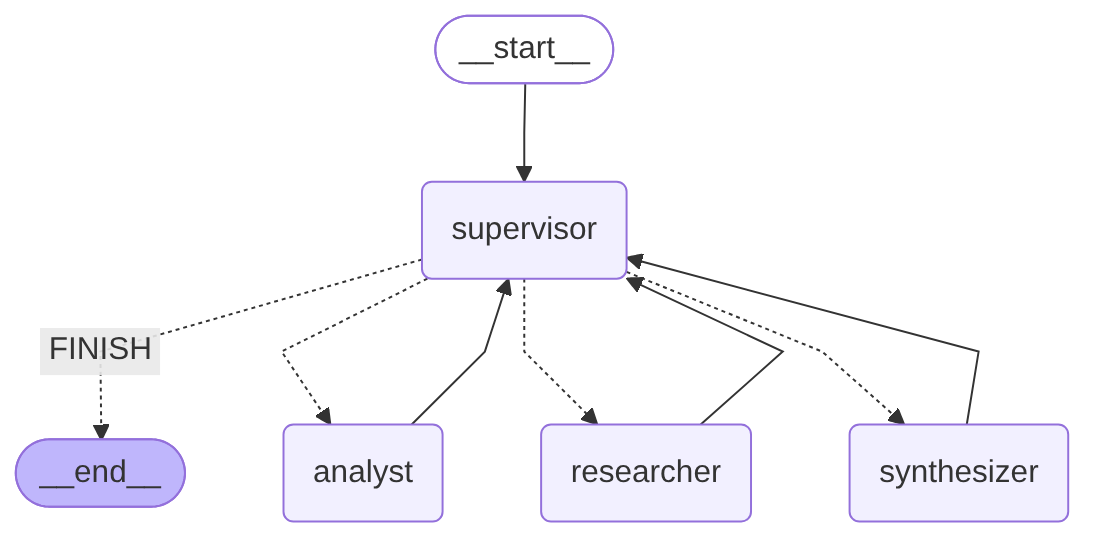

In [2]:
print(app.get_graph().draw_mermaid())
display(Image("graph.png"))

## 2. Ejecución

Cada bloque es un paso del grafo: 🧭 decisión del supervisor (con el estado de la rúbrica), 🔎 investigador, 📊 analista, ✍️ sintetizador.

In [3]:
state = await run_task(app, DEFAULT_TASK)
save_trace(state, __import__("pathlib").Path("traces/notebook_run.json"))

👤 Usuario: Compará las opiniones de los clientes sobre los auriculares SoundMax Pro y AudioZen X: ¿cuál tiene mejor sentimiento en las reseñas, cuál es el precio promedio de cada uno y cuál me recomendarías?



🧭 supervisor (paso 1) [investigación✗ análisis✗ consistencia✗ respuesta✗] → researcher
   motivo: La investigación no está completa y se requiere la información inicial de los productos para que el análisis pueda avanzar.
   instrucción: Busca reseñas y precios externos para los auriculares SoundMax Pro y AudioZen X, asegurando al menos 3 reseñas y 1 precio por cada producto.



🔎 researcher (ronda 1) | herramientas: search_reviews(SoundMax Pro), search_prices(SoundMax Pro), search_reviews(AudioZen X), search_prices(AudioZen X)
   **Resumen de investigación:**

- **SoundMax Pro**: Se encontraron 6 reseñas de clientes y 3 precios en diferentes tiendas online (TecnoShop, AudioWorld, MegaStore).
- **AudioZen X**: Se encontraron 6 reseñas de clientes y 3 precios en diferentes tiendas online (TecnoShop, AudioWorld, MegaStore).

No



🧭 supervisor (paso 2) [investigación✓ análisis✗ consistencia✗ respuesta✗] → analyst
   motivo: La investigación ya está completa, pero falta realizar el análisis de los datos recolectados.
   instrucción: Analizar las reseñas y precios obtenidos para SoundMax Pro y AudioZen X, calculando el sentimiento, las estadísticas y los precios promedio de cada uno.



📊 analyst (ronda 1) | herramientas: compute_statistics(SoundMax Pro), analyze_sentiment(SoundMax Pro), compute_statistics(AudioZen X), analyze_sentiment(AudioZen X)
   A continuación se presentan los resultados del análisis de estadísticas y sentimiento para ambos productos, utilizando exclusivamente los datos provistos por las herramientas:

---

### **1. SoundMax Pro**
* **Estadísticas:**
  * **Cantidad de reseñas:** 6
  * **Puntaje promedio:** 4.17 (sobre 5)
  



🧭 supervisor (paso 3) [investigación✓ análisis✓ consistencia✓ respuesta✗] → synthesizer
   motivo: La investigación y el análisis están completos y son consistentes, por lo que el synthesizer debe generar la respuesta final para el usuario.
   instrucción: Redactar la respuesta final comparando las opiniones de los clientes sobre los auriculares SoundMax Pro y AudioZen X, indicando cuál tiene mejor sentimiento, el precio promedio de cada uno y tu recomendación basándote en



✍️ synthesizer (ronda 1)



🧭 supervisor (paso 4) [investigación✓ análisis✓ consistencia✓ respuesta✓] → FINISH
   motivo: la respuesta final está lista

✅ Respuesta final (12.1 s):

El **SoundMax Pro** tiene mejor sentimiento en las reseñas, con un puntaje de sentimiento de 0.33, un 50,0% de opiniones positivas y un promedio de 4,17. En contraste, el **AudioZen X** registra un sentimiento de 0,0, un 33,3% de positivas y un promedio de 2,83.
El precio promedio del SoundMax Pro es de $182.000, mientras que el AudioZen X cuesta en promedio $88.667. 
Existe una tensión en los datos: aunque el AudioZen X es mucho más barato (su mayor pro), también presenta problemas de durabilidad y opiniones polarizadas sobre su comodidad. 
Te recomiendo el **SoundMax Pro**, ya que justifica su mayor inversión con una calidad general muy superior y clientes notablemente más satisfechos.


## 3. Decisiones del supervisor

Qué eligió en cada paso, por qué, y si una regla del sistema corrigió al LLM (`overridden`).

In [4]:
rows = ["| Paso | Rúbrica | Destino | Corregido | Motivo |", "|---|---|---|---|---|"]
for d in state["decisions"]:
    rubric = " ".join(("✓" if v else "✗") for v in d.rubric.values())
    rows.append(f"| {d.step} | {rubric} | **{d.next_agent}** | {'sí' if d.overridden else ''} | {d.reason} |")
display(Markdown("\n".join(rows)))

| Paso | Rúbrica | Destino | Corregido | Motivo |
|---|---|---|---|---|
| 1 | ✗ ✗ ✗ ✗ | **researcher** |  | La investigación no está completa y se requiere la información inicial de los productos para que el análisis pueda avanzar. |
| 2 | ✓ ✗ ✗ ✗ | **analyst** |  | La investigación ya está completa, pero falta realizar el análisis de los datos recolectados. |
| 3 | ✓ ✓ ✓ ✗ | **synthesizer** |  | La investigación y el análisis están completos y son consistentes, por lo que el synthesizer debe generar la respuesta final para el usuario. |
| 4 | ✓ ✓ ✓ ✓ | **FINISH** |  | la respuesta final está lista |

## 4. Quién aportó qué

Cada contribución queda registrada con el agente, la ronda (1 = primer intento, 2 = refinamiento), la instrucción recibida y las herramientas usadas.

In [5]:
rows = ["| Agente | Ronda | Herramientas | Error | Instrucción |", "|---|---|---|---|---|"]
for c in state["contributions"]:
    error = (c.error or "")[:80]
    rows.append(f"| {c.agent} | {c.round} | {', '.join(c.tools_used) or '—'} | {error} | {c.instruction[:120]} |")
display(Markdown("\n".join(rows)))

| Agente | Ronda | Herramientas | Error | Instrucción |
|---|---|---|---|---|
| researcher | 1 | search_reviews(SoundMax Pro), search_prices(SoundMax Pro), search_reviews(AudioZen X), search_prices(AudioZen X) |  | Busca reseñas y precios externos para los auriculares SoundMax Pro y AudioZen X, asegurando al menos 3 reseñas y 1 preci |
| analyst | 1 | compute_statistics(SoundMax Pro), analyze_sentiment(SoundMax Pro), compute_statistics(AudioZen X), analyze_sentiment(AudioZen X) |  | Analizar las reseñas y precios obtenidos para SoundMax Pro y AudioZen X, calculando el sentimiento, las estadísticas y l |
| synthesizer | 1 | — |  | Redactar la respuesta final comparando las opiniones de los clientes sobre los auriculares SoundMax Pro y AudioZen X, in |

## 5. Resultado del análisis (estructurado)

Los números salen de las herramientas, no del texto del LLM.

In [6]:
analysis = state["analysis"]
if analysis is None:
    display(Markdown("**No hay análisis**: el analista no pudo completar su tarea (ver sus errores en la tabla de contribuciones)."))
else:
    rows = ["| Producto | Reseñas | Puntaje | Sentimiento | % positivas | Precio prom. | Más barato | Pros | Contras |",
            "|---|---|---|---|---|---|---|---|---|"]
    for p in analysis.products:
        price = f"${p.avg_price:,.0f}" if p.avg_price else "—"
        cheapest = f"{p.best_store} (${p.min_price:,})" if p.min_price else "—"
        rows.append(f"| {p.product} | {p.review_count} | {p.avg_rating} | {p.sentiment_score} | {p.positive_pct}% | "
                    f"{price} | {cheapest} | {', '.join(p.pros)} | {', '.join(p.cons)} |")
    display(Markdown("\n".join(rows)))

| Producto | Reseñas | Puntaje | Sentimiento | % positivas | Precio prom. | Más barato | Pros | Contras |
|---|---|---|---|---|---|---|---|---|
| SoundMax Pro | 6 | 4.17 | 0.33 | 50.0% | $182,000 | AudioWorld ($175,000) | sonido, batería, comodidad | conexión |
| AudioZen X | 6 | 2.83 | 0.0 | 33.3% | $88,667 | MegaStore ($85,000) | precio, sonido, comodidad | comodidad, durabilidad |

## 6. Respuesta final

In [7]:
display(Markdown(state["final_answer"]))

El **SoundMax Pro** tiene mejor sentimiento en las reseñas, con un puntaje de sentimiento de 0.33, un 50,0% de opiniones positivas y un promedio de 4,17. En contraste, el **AudioZen X** registra un sentimiento de 0,0, un 33,3% de positivas y un promedio de 2,83.
El precio promedio del SoundMax Pro es de $182.000, mientras que el AudioZen X cuesta en promedio $88.667. 
Existe una tensión en los datos: aunque el AudioZen X es mucho más barato (su mayor pro), también presenta problemas de durabilidad y opiniones polarizadas sobre su comodidad. 
Te recomiendo el **SoundMax Pro**, ya que justifica su mayor inversión con una calidad general muy superior y clientes notablemente más satisfechos.